In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df.columns.tolist()

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'smoking_history',
 'bmi',
 'HbA1c_level',
 'blood_glucose_level',
 'diabetes']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [5]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [6]:
df["diabetes"].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [7]:
df = df.drop_duplicates().dropna()
print("Dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape: (96146, 9)
Remaining missing values: 0


In [8]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96146, 8)
y shape: (96146,)


In [9]:
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.head())

    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   gender_Male  gender_Other  smoking_history_current  smoking_history_ever  \
0            0             0                        0                     0   
1            0             0                        0                     0   
2            1             0                        0                     0   
3            0             0                        1                     0   
4            1             0                        1                     0   

   smoking_history_former  smoking_his

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)

Training: (76916, 13) Testing: (19230, 13)


In [11]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Naive Bayes training completed!")

Naive Bayes training completed!


In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", round(accuracy_score(y_test, y_pred)*100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 86.37 %

Confusion Matrix:
 [[15264  2270]
 [  351  1345]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.87      0.92     17534
           1       0.37      0.79      0.51      1696

    accuracy                           0.86     19230
   macro avg       0.67      0.83      0.71     19230
weighted avg       0.92      0.86      0.88     19230



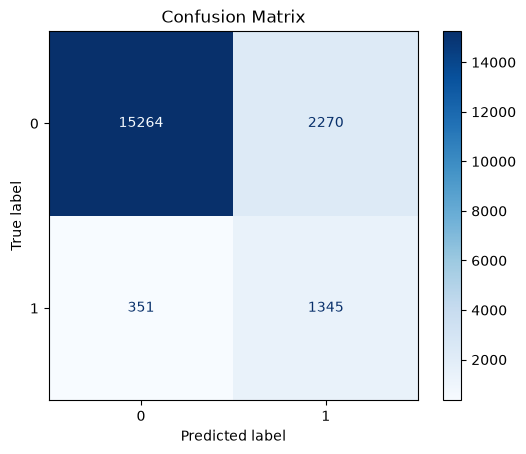

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

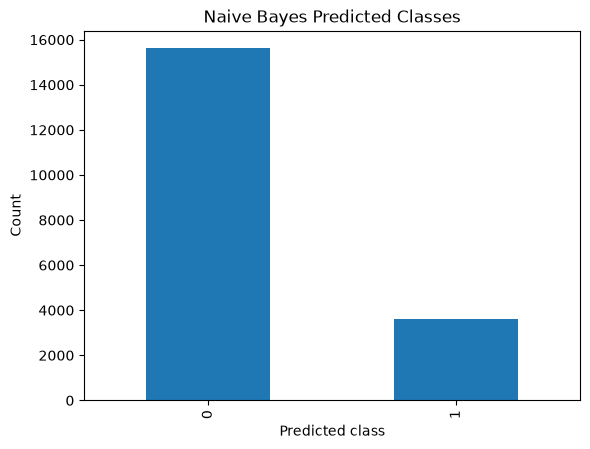

In [14]:
pd.Series(y_pred).value_counts().sort_index().plot(kind="bar")
plt.title("Naive Bayes Predicted Classes")
plt.xlabel("Predicted class")
plt.ylabel("Count")
plt.show()

In [15]:
new_person = pd.DataFrame([{
    "gender": "Female", "age": 45, "hypertension": 0,
    "heart_disease": 0, "smoking_history": "never",
    "bmi": 27.5, "HbA1c_level": 5.8, "blood_glucose_level": 140
}])
new_person = pd.get_dummies(pd.concat([df.drop(columns=["diabetes"]), new_person], ignore_index=True), drop_first=True, dtype=int).tail(1)
new_person = new_person.reindex(columns=X.columns, fill_value=0)
print("Predicted diabetes class:", model.predict(new_person)[0])
print("Note: Educational demonstration, not a medical diagnosis.")

Predicted diabetes class: 0
Note: Educational demonstration, not a medical diagnosis.
